In [1]:
import pandas as pd

In [3]:
rfm = pd.read_csv("rfm_output.csv")
df = pd.read_csv("online_retail_cleaned.csv")

In [5]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [7]:
data_start = df["InvoiceDate"].min()
data_end = df["InvoiceDate"].max()

data_duration_days = (data_end - data_start).days
data_duration_years = data_duration_days / 365

print("Data starts:", data_start.date())
print("Data ends:", data_end.date())
print("Total duration:", round(data_duration_years, 2), "years")

Data starts: 2009-12-01
Data ends: 2011-12-09
Total duration: 2.02 years


In [11]:
df_merged = df.merge(rfm[["Customer ID", "Segment"]], on="Customer ID", how="left")

# Average order value per segment = total revenue / number of distinct invoices, grouped by segment
aov = df_merged.groupby("Segment").apply(
    lambda x: x.groupby("Invoice")["Revenue"].sum().mean()
).reset_index()
aov.columns = ["Segment", "Avg_Order_Value"]

# Average orders per customer per year per segment
orders_per_customer = rfm.groupby("Segment")["Frequency"].mean() / data_duration_years
orders_per_customer = orders_per_customer.reset_index()
orders_per_customer.columns = ["Segment", "Orders_Per_Year"]

lifespan_map = {
    "Champion": 3.0,
    "Loyal Customer": 2.0,
    "Potential Loyalist": 1.5,
    "At Risk": 1.0,
    "About to Sleep": 0.5,
    "Lost": 0.3
}

print(aov)

              Segment  Avg_Order_Value
0      About to Sleep       358.401878
1             At Risk       397.513907
2            Champion       561.636321
3                Lost       356.925540
4      Loyal Customer       398.021703
5  Potential Loyalist       484.247277


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9884\3742974533.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  aov = df_merged.groupby("Segment").apply(


In [21]:
clv_table = aov.merge(orders_per_customer, on="Segment")
clv_table["Lifespan_Years"] = clv_table["Segment"].map(lifespan_map)

# The CLV formula
clv_table["CLV"] = (
    clv_table["Avg_Order_Value"] *
    clv_table["Orders_Per_Year"] *
    clv_table["Lifespan_Years"]
)

clv_table["CLV"] = clv_table["CLV"].round(2)
clv_table = clv_table.sort_values("CLV", ascending=False)

clv_table[["Segment", "Avg_Order_Value", "Orders_Per_Year", "Lifespan_Years", "CLV"]]

,Segment,Avg_Order_Value,Orders_Per_Year,Lifespan_Years,CLV
2,Champion,561.636321,8.763294,3.0,14765.35
4,Loyal Customer,398.021703,3.942495,2.0,3138.40
1,At Risk,397.513907,2.457668,1.0,976.96
5,Potential Loyalist,484.247277,0.879622,1.5,638.93
3,Lost,356.925540,0.993906,0.3,106.43
0,About to Sleep,358.401878,0.494580,0.5,88.63


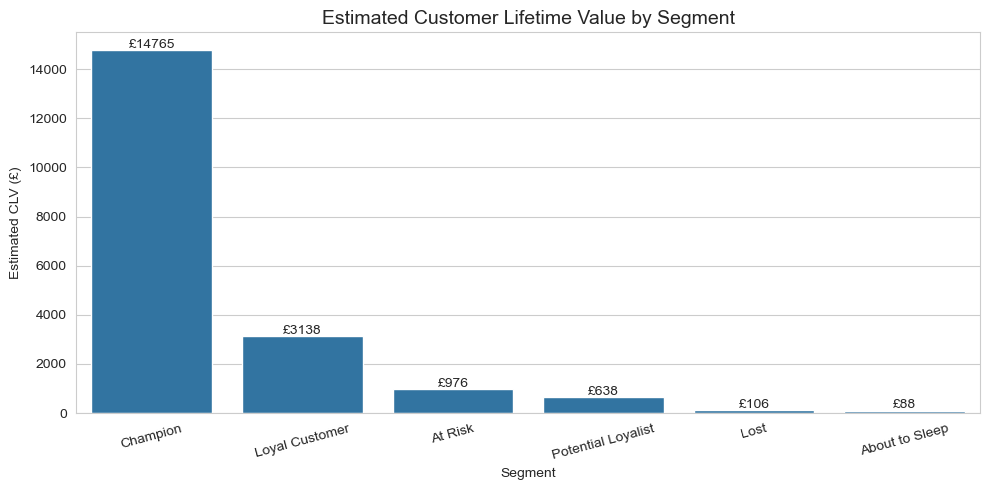

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(10, 5))
sns.barplot(data=clv_table, x="Segment", y="CLV")

plt.title("Estimated Customer Lifetime Value by Segment", fontsize=14)
plt.xlabel("Segment")
plt.ylabel("Estimated CLV (£)")
plt.xticks(rotation=15)

for i, row in clv_table.reset_index().iterrows():
    plt.text(i, row["CLV"] + 100, f"£{int(row['CLV'])}", ha="center", fontsize=10)

plt.tight_layout()
plt.show()

In [27]:
clv_table.to_csv("clv_output.csv", index=False)
print("CLV table saved!")

CLV table saved!
